# Eksploracyjna analiza danych (EDA): ceny domów w Ames, Iowa

**Źródło:** [Kaggle – House Prices: Advanced Regression Techniques](https://www.kaggle.com/c/house-prices-advanced-regression-techniques)
**Dane:** sprzedaż domów w Ames (Iowa, USA), 1460 transakcji z lat 2006–2010, 79 zmiennych opisujących nieruchomość + cena sprzedaży.
**Cel:** przeprowadzić eksploracyjną analizę danych, odkryć interesujące zależności i przedstawić najważniejsze wnioski na wykresach.

**Zakres notatnika** (zgodnie ze slajdami 42–45):

1. Pytania naprowadzające: zmienna docelowa, typy zmiennych, statystyki opisowe, braki danych
2. Analiza zmiennej docelowej: histogram, wykres pudełkowy, statystyki, rozkład normalny
3. Co wpływa na cenę domu? Hipoteza „Większe domy są droższe”

> Powierzchnie w zbiorze są podane w **stopach kwadratowych** (sq ft; 1 sq ft ≈ 0,093 m²), a ceny w **dolarach amerykańskich**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

NIEBIESKI, POMARANCZ = "#2E6F8E", "#D07A2D"

# oś w tysiącach dolarów – czytelniejsze etykiety niż 700000
tys = mtick.FuncFormatter(lambda v, _: f"{v / 1000:,.0f}")

## Wczytanie danych

W pliku `train.csv` brak danych jest zapisany jako tekst `NA`. Domyślnie `pandas` zamienia na `NaN` zarówno `"NA"`, jak i `"None"`. To pułapka, bo w kolumnie `MasVnrType` wartość `None` jest **prawdziwą kategorią** („brak okładziny murowanej”), a nie brakiem danych. Dlatego wyłączamy domyślną listę braków (`keep_default_na=False`) i wskazujemy tylko `"NA"`.

In [2]:
KANDYDACI = [Path("train.csv"), Path("data/train.csv"),
             Path("house-prices-advanced-regression-techniques/train.csv")]
# kopia danych na GitHubie – użyta tylko wtedy, gdy plik nie leży obok notatnika
URL_ZAPASOWY = ("https://raw.githubusercontent.com/maydaythecoder/HousePricePredictionModel/"
                "main/house-prices-advanced-regression-techniques/train.csv")

zrodlo = next((p for p in KANDYDACI if p.exists()), URL_ZAPASOWY)
df = pd.read_csv(zrodlo, keep_default_na=False, na_values=["NA"])

print(f"Wczytano z: {zrodlo}")
print(f"Wiersze: {df.shape[0]}, kolumny: {df.shape[1]}")
df.head()

Wczytano z: train.csv
Wiersze: 1460, kolumny: 81


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,...,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,...,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,None,0.0,TA,TA,CBlock,...,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,...,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,None,0.0,TA,TA,BrkTil,...,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,...,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


---
## 1. Pytania naprowadzające

### 1.1 Jaka jest zmienna docelowa?

In [3]:
CEL = "SalePrice"
print(f"Zmienna docelowa: {CEL}")
print(f"Typ: {df[CEL].dtype}, liczba różnych wartości: {df[CEL].nunique()}, braki: {df[CEL].isna().sum()}")
print(f"Pozostałe kolumny: {df.shape[1] - 1} (w tym identyfikator `Id`, więc cech opisowych jest {df.shape[1] - 2})")

Zmienna docelowa: SalePrice
Typ: int64, liczba różnych wartości: 663, braki: 0
Pozostałe kolumny: 80 (w tym identyfikator `Id`, więc cech opisowych jest 79)


**Odpowiedź:** zmienną docelową jest **`SalePrice`**, czyli cena sprzedaży domu w dolarach. To zmienna **ilościowa, ciągła** (663 różne wartości, bez braków), więc przewidywanie ceny to problem **regresji**. Pozostałe 79 kolumn (poza kolumną `Id`) to cechy opisujące nieruchomość.

### 1.2 Jakie rodzaje zmiennych są w zbiorze?

Najpierw typy techniczne (`df.dtypes`):

In [4]:
typy = df.dtypes.astype(str)
display(typy.value_counts().rename("liczba kolumn").to_frame())

for typ, kolumny in typy.groupby(typy):
    print(f"\n[{typ}] – {len(kolumny)} kolumn:")
    print(", ".join(kolumny.index))

,liczba kolumn
str,43
int64,35
float64,3



[float64] – 3 kolumn:
LotFrontage, MasVnrArea, GarageYrBlt

[int64] – 35 kolumn:
Id, MSSubClass, LotArea, OverallQual, OverallCond, YearBuilt, YearRemodAdd, BsmtFinSF1, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, TotRmsAbvGrd, Fireplaces, GarageCars, GarageArea, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, MiscVal, MoSold, YrSold, SalePrice

[str] – 43 kolumn:
MSZoning, Street, Alley, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinType2, Heating, HeatingQC, CentralAir, Electrical, KitchenQual, Functional, FireplaceQu, GarageType, GarageFinish, GarageQual, GarageCond, PavedDrive, PoolQC, Fence, MiscFeature, SaleType, SaleCondition


Typ techniczny to jednak nie wszystko. Liczba w kolumnie nie musi oznaczać wielkości, którą da się sensownie uśredniać. Dlatego dodatkowo klasyfikujemy kolumny **semantycznie**, na podstawie opisu w `data_description.txt`:

,liczba kolumn
"ilościowe ciągłe (powierzchnie, długości)",19
"ilościowe dyskretne (liczniki: łazienki, pokoje…)",9
"czasowe (lata, miesiąc sprzedaży)",5
porządkowe liczbowe (oceny 1–10),2
kategoryczne zakodowane liczbą (MSSubClass),1
porządkowe tekstowe (skala jakości Ex…Po),10
kategoryczne nominalne (tekstowe),33
identyfikator (Id),1
zmienna docelowa (SalePrice),1


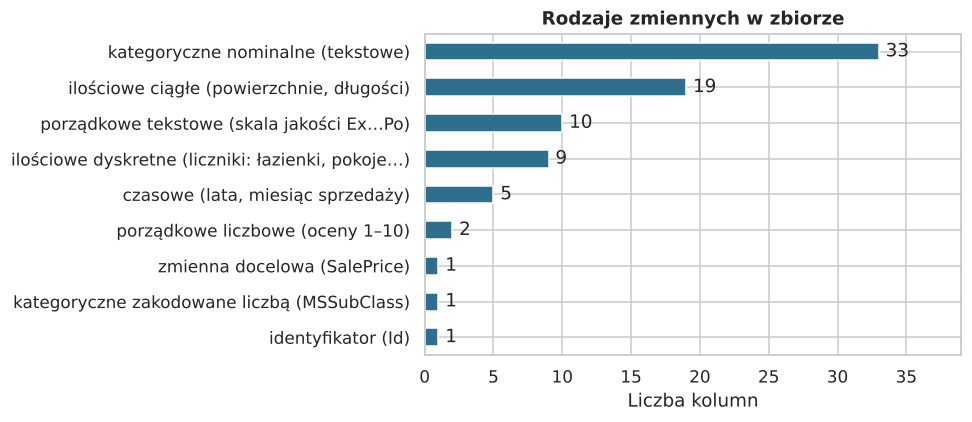

Największa liczba kategorii w kolumnie tekstowej: 25 (Neighborhood)


In [5]:
kol_liczbowe = df.select_dtypes(include="number").columns
kol_tekstowe = df.select_dtypes(exclude="number").columns

ID = ["Id"]
KAT_LICZBOWE = ["MSSubClass"]                         # kod klasy budynku, nie ilość
PORZ_LICZBOWE = ["OverallQual", "OverallCond"]        # oceny w skali 1–10
CZASOWE = ["YearBuilt", "YearRemodAdd", "GarageYrBlt", "MoSold", "YrSold"]
DYSKRETNE = ["BsmtFullBath", "BsmtHalfBath", "FullBath", "HalfBath", "BedroomAbvGr",
             "KitchenAbvGr", "TotRmsAbvGrd", "Fireplaces", "GarageCars"]   # liczniki
CIAGLE = [c for c in kol_liczbowe if c not in ID + KAT_LICZBOWE + PORZ_LICZBOWE + CZASOWE + DYSKRETNE + [CEL]]
PORZ_TEKSTOWE = ["ExterQual", "ExterCond", "BsmtQual", "BsmtCond", "HeatingQC", "KitchenQual",
                 "FireplaceQu", "GarageQual", "GarageCond", "PoolQC"]    # skala Ex/Gd/TA/Fa/Po
NOMINALNE = [c for c in kol_tekstowe if c not in PORZ_TEKSTOWE]

rodzaje = {
    "ilościowe ciągłe (powierzchnie, długości)": CIAGLE,
    "ilościowe dyskretne (liczniki: łazienki, pokoje…)": DYSKRETNE,
    "czasowe (lata, miesiąc sprzedaży)": CZASOWE,
    "porządkowe liczbowe (oceny 1–10)": PORZ_LICZBOWE,
    "kategoryczne zakodowane liczbą (MSSubClass)": KAT_LICZBOWE,
    "porządkowe tekstowe (skala jakości Ex…Po)": PORZ_TEKSTOWE,
    "kategoryczne nominalne (tekstowe)": NOMINALNE,
    "identyfikator (Id)": ID,
    "zmienna docelowa (SalePrice)": [CEL],
}
assert sum(len(v) for v in rodzaje.values()) == df.shape[1], "każda kolumna powinna trafić do dokładnie jednej grupy"

podsumowanie = pd.Series({k: len(v) for k, v in rodzaje.items()}, name="liczba kolumn")
display(podsumowanie.to_frame())

fig, ax = plt.subplots(figsize=(9, 4))
podsumowanie.sort_values().plot.barh(ax=ax, color=NIEBIESKI)
for i, v in enumerate(podsumowanie.sort_values()):
    ax.text(v + 0.5, i, str(v), va="center")
ax.set(title="Rodzaje zmiennych w zbiorze", xlabel="Liczba kolumn", ylabel="")
ax.set_xlim(0, podsumowanie.max() + 6)
plt.tight_layout()
plt.show()

print("Największa liczba kategorii w kolumnie tekstowej:",
      df[kol_tekstowe].nunique().max(), f"({df[kol_tekstowe].nunique().idxmax()})")

**Odpowiedź:**

- **Liczbowych** jest 38 kolumn (35 `int64` + 3 `float64`), **tekstowych** 43. Zbiór ma charakter mieszany.
- Kolumny tekstowe to **zmienne kategoryczne** (od 2 do 25 różnych wartości, np. `Neighborhood`), a nie swobodny tekst. **Zmiennych czysto tekstowych nie ma**, więc nie potrzeba analizy tekstu.
- Nie każda kolumna liczbowa jest „prawdziwą” liczbą. `MSSubClass` to **kod kategorii** (średnia z kodów byłaby bez sensu), `OverallQual` i `OverallCond` to **oceny porządkowe**, a `YearBuilt`, `MoSold`, `YrSold` to **daty**. Typ techniczny trzeba więc interpretować przez opis kolumn.
- Część zmiennych tekstowych ma naturalny porządek (skala jakości `Ex > Gd > TA > Fa > Po`), więc jest **porządkowa**, a nie nominalna.

### 1.3 Podstawowe statystyki opisowe (`df.describe()`)

In [6]:
display(df.describe().T.round(1))

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.5,421.6,1.0,365.8,730.5,1095.2,1460.0
MSSubClass,1460.0,56.9,42.3,20.0,20.0,50.0,70.0,190.0
LotFrontage,1201.0,70.0,24.3,21.0,59.0,69.0,80.0,313.0
LotArea,1460.0,10516.8,9981.3,1300.0,7553.5,9478.5,11601.5,215245.0
OverallQual,1460.0,6.1,1.4,1.0,5.0,6.0,7.0,10.0
OverallCond,1460.0,5.6,1.1,1.0,5.0,5.0,6.0,9.0
YearBuilt,1460.0,1971.3,30.2,1872.0,1954.0,1973.0,2000.0,2010.0
YearRemodAdd,1460.0,1984.9,20.6,1950.0,1967.0,1994.0,2004.0,2010.0
MasVnrArea,1452.0,103.7,181.1,0.0,0.0,0.0,166.0,1600.0
BsmtFinSF1,1460.0,443.6,456.1,0.0,0.0,383.5,712.2,5644.0


In [7]:
# zmienne kategoryczne: liczba kategorii, najczęstsza wartość i jej liczność
display(df.describe(exclude="number").T)

,count,unique,top,freq
MSZoning,1460,5,RL,1151
Street,1460,2,Pave,1454
Alley,91,2,Grvl,50
LotShape,1460,4,Reg,925
LandContour,1460,4,Lvl,1311
Utilities,1460,2,AllPub,1459
LotConfig,1460,5,Inside,1052
LandSlope,1460,3,Gtl,1382
Neighborhood,1460,25,NAmes,225
Condition1,1460,9,Norm,1260


**Obserwacje:**

- **Cena:** średnia (180 921 USD) jest wyraźnie wyższa od mediany (163 000 USD), a maksimum (755 000 USD) jest ponad 20 razy większe od minimum (34 900 USD). To pierwsza wskazówka, że rozkład ceny jest prawoskośny (szczegóły w sekcji 2).
- **Powierzchnie są mocno prawoskośne.** Mediana `LotArea` to ok. 9,5 tys. sq ft, a maksimum aż 215 tys. sq ft. Dom o największej powierzchni mieszkalnej (`GrLivArea` = 5642 sq ft) jest prawie 4× większy od mediany (1464 sq ft).
- **Zera nie oznaczają braków danych.** W wielu kolumnach powierzchniowych mediana to 0 (`2ndFlrSF`, `WoodDeckSF`, `MasVnrArea`, `BsmtFinSF2`…). Dom po prostu nie ma piętra, tarasu czy okładziny. Rzadkie elementy: basen ma tylko 7 domów (`PoolArea` > 0), a `MiscVal` > 0 tylko 52.
- **Statystyki zmiennych kodowych nie mają sensu.** Średnia `MSSubClass` (56,9) czy `MoSold` (6,3) nie niesie informacji. Sprzedaże obejmują tylko 5 lat (`YrSold`: 2006–2010).
- **Zmienne prawie stałe:** `Utilities` (1459 z 1460 domów ma wartość `AllPub`) i `Street` (1454 × `Pave`) praktycznie nie różnicują domów.

### 1.4 Braki danych i ich znaczenie

W pliku `train.csv` brak danych w 19 kolumnach jest zapisany jako `NA`. Zgodnie z `data_description.txt` w większości tych kolumn **`NA` nie oznacza „nie wiemy”, tylko „domu nie ma takiego elementu”** (np. `NA` w `GarageType` = „brak garażu”). Zweryfikujemy to na danych: jeśli `NA` w `BsmtQual` oznacza brak piwnicy, to te domy powinny mieć `TotalBsmtSF == 0`.

In [8]:
# kolumna -> (znaczenie NA wg data_description.txt, maska domów, które faktycznie nie mają tego elementu)
# maska None = brak kolumny liczbowej do weryfikacji; opieramy się wyłącznie na opisie
NIE_MA_CECHY = {
    "Alley":        ("brak dostępu do alei", None),
    "BsmtQual":     ("brak piwnicy", df.TotalBsmtSF == 0),
    "BsmtCond":     ("brak piwnicy", df.TotalBsmtSF == 0),
    "BsmtExposure": ("brak piwnicy", df.TotalBsmtSF == 0),
    "BsmtFinType1": ("brak piwnicy", df.TotalBsmtSF == 0),
    "BsmtFinType2": ("brak piwnicy", df.TotalBsmtSF == 0),
    "FireplaceQu":  ("brak kominka", df.Fireplaces == 0),
    "GarageType":   ("brak garażu", df.GarageArea == 0),
    "GarageYrBlt":  ("brak garażu (nie ma roku budowy)", df.GarageArea == 0),
    "GarageFinish": ("brak garażu", df.GarageArea == 0),
    "GarageQual":   ("brak garażu", df.GarageArea == 0),
    "GarageCond":   ("brak garażu", df.GarageArea == 0),
    "PoolQC":       ("brak basenu", df.PoolArea == 0),
    "Fence":        ("brak ogrodzenia", None),
    "MiscFeature":  ("brak dodatkowych udogodnień", df.MiscVal == 0),
}

wiersze = []
for kol in df.columns[df.isna().any()]:
    n = int(df[kol].isna().sum())
    if kol in NIE_MA_CECHY:
        znaczenie, maska = NIE_MA_CECHY[kol]
        brak_cechy = n if maska is None else int((df[kol].isna() & maska).sum())
    else:
        znaczenie, brak_cechy = "opis nie przewiduje NA, więc to realny brak informacji", 0
    wiersze.append({"kolumna": kol, "braki": n, "% wierszy": round(100 * n / len(df), 1),
                    "NA oznacza": znaczenie, "z tego: brak cechy": brak_cechy,
                    "z tego: prawdziwy brak danych": n - brak_cechy})

braki = pd.DataFrame(wiersze).set_index("kolumna").sort_values("braki", ascending=False)
display(braki)

print(f"Kolumn z jakimikolwiek brakami: {len(braki)}")
print(f"Kolumn, w których występują PRAWDZIWE braki danych: {(braki['z tego: prawdziwy brak danych'] > 0).sum()}")
print(f"Wartość 'None' w MasVnrType (prawdziwa kategoria, nie brak): {(df.MasVnrType == 'None').sum()} domów")

,braki,% wierszy,NA oznacza,z tego: brak cechy,z tego: prawdziwy brak danych
kolumna,,,,,
PoolQC,1453,99.5,brak basenu,1453,0
MiscFeature,1406,96.3,brak dodatkowych udogodnień,1406,0
Alley,1369,93.8,brak dostępu do alei,1369,0
Fence,1179,80.8,brak ogrodzenia,1179,0
FireplaceQu,690,47.3,brak kominka,690,0
LotFrontage,259,17.7,"opis nie przewiduje NA, więc to realny brak in...",0,259
GarageCond,81,5.5,brak garażu,81,0
GarageType,81,5.5,brak garażu,81,0
GarageYrBlt,81,5.5,brak garażu (nie ma roku budowy),81,0


Kolumn z jakimikolwiek brakami: 19
Kolumn, w których występują PRAWDZIWE braki danych: 6
Wartość 'None' w MasVnrType (prawdziwa kategoria, nie brak): 864 domów


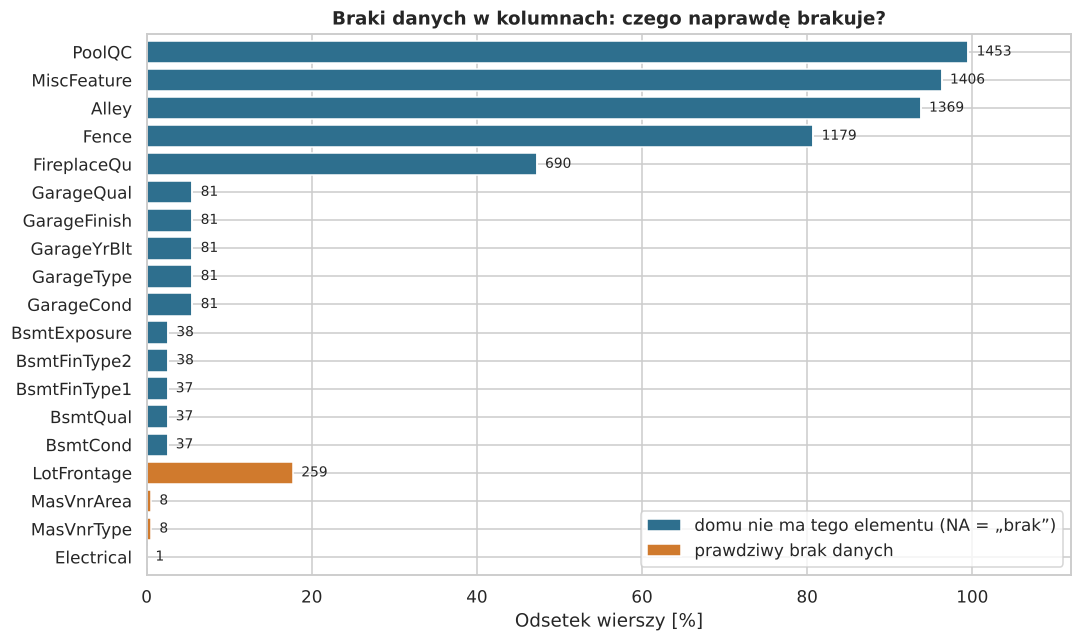

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
wykres = braki[["z tego: brak cechy", "z tego: prawdziwy brak danych"]].sort_values(
    by=["z tego: brak cechy", "z tego: prawdziwy brak danych"], ascending=True)
wykres = wykres / len(df) * 100
wykres.plot.barh(stacked=True, ax=ax, color=[NIEBIESKI, POMARANCZ], width=0.8)
ax.set(title="Braki danych w kolumnach: czego naprawdę brakuje?",
       xlabel="Odsetek wierszy [%]", ylabel="")
ax.legend(["domu nie ma tego elementu (NA = „brak”)", "prawdziwy brak danych"], loc="lower right")
ax.set_xlim(0, 112)
for i, kol in enumerate(wykres.index):          # liczba brakujących wierszy przy każdym słupku
    ax.text(wykres.loc[kol].sum() + 1, i, f"{braki.loc[kol, 'braki']}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

**Odpowiedź:**

- Braki występują w **19 kolumnach**, ale w większości z nich **`NA` to informacja, a nie dziura w danych**. Dla garażu, piwnicy, kominka, basenu, `MiscFeature` weryfikacja potwierdza to co do jednego wiersza (np. wszystkie 81 domów bez `GarageType` ma `GarageArea` = 0, a wszystkie 690 domów bez `FireplaceQu` ma `Fireplaces` = 0).
- Dlatego `PoolQC` (99,5% „braków”), `MiscFeature` (96%), `Alley` (94%) czy `Fence` (81%) nie są „zepsutymi” kolumnami. Są prawie puste, bo **większość domów nie ma basenu, alei czy ogrodzenia**. Usuwanie takich kolumn jako „kolumn z brakami” oznaczałoby utratę informacji.
- **Prawdziwe braki danych** dotyczą tylko sześciu kolumn:
  - `LotFrontage` (259 domów, 17,7%): brak informacji o długości frontu działki,
  - `MasVnrType` i `MasVnrArea` (po 8, te same domy): brak informacji o okładzinie murowanej,
  - `Electrical` (1 dom, `Id` 1380),
  - po jednym domu w `BsmtExposure` (`Id` 949) i `BsmtFinType2` (`Id` 333). Te domy mają piwnicę, więc `NA` nie oznacza tu „brak piwnicy”.
- Przy modelowaniu braki „brak cechy” należy kodować jako **osobną kategorię** (np. „Brak”), a nie imputować. Tylko prawdziwe braki wymagają imputacji lub usunięcia wierszy.

---
## 2. Analiza zmiennej docelowej (`SalePrice`)

**Pytania:** Jaki jest rozkład cen? Czy są wartości odstające? Jaka jest średnia i mediana ceny? Czy ceny mają rozkład normalny?

### 2.1 Histogram cen: wpływ liczby przedziałów (`bins` = 10, 30, 50)

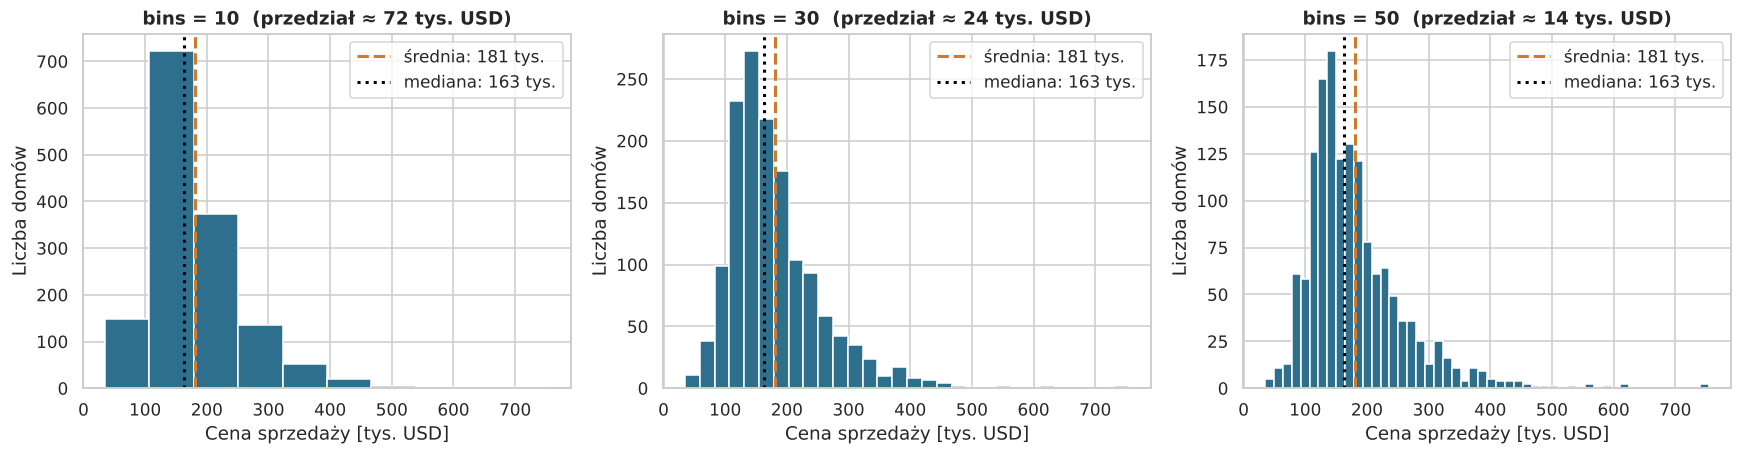

Współczynnik skośności: 1.88  (0 = rozkład symetryczny, > 1 = silna skośność prawostronna)


In [10]:
y = df[CEL]

fig, osie = plt.subplots(1, 3, figsize=(16, 4.3), sharex=True)
for ax, b in zip(osie, (10, 30, 50)):
    ax.hist(y, bins=b, color=NIEBIESKI, edgecolor="white")
    ax.axvline(y.mean(), color=POMARANCZ, ls="--", lw=2, label=f"średnia: {y.mean() / 1000:.0f} tys.")
    ax.axvline(y.median(), color="black", ls=":", lw=2, label=f"mediana: {y.median() / 1000:.0f} tys.")
    szer = (y.max() - y.min()) / b
    ax.set(title=f"bins = {b}  (przedział ≈ {szer / 1000:.0f} tys. USD)",
           xlabel="Cena sprzedaży [tys. USD]", ylabel="Liczba domów")
    ax.xaxis.set_major_formatter(tys)
    ax.legend()
plt.tight_layout()
plt.show()

print(f"Współczynnik skośności: {y.skew():.2f}  (0 = rozkład symetryczny, > 1 = silna skośność prawostronna)")

**Odpowiedź:**

- **`bins` = 10** daje bardzo grube przedziały (ok. 72 tys. USD). Widać jeden szczyt i długi prawy ogon, ale gubi się szczegółowa struktura rozkładu: najwyższy słupek (ok. 107–179 tys. USD) obejmuje prawie połowę wszystkich domów.
- **`bins` = 30** to dobry kompromis. Wyraźnie widać, że szczyt przypada na ok. 130–150 tys. USD i że rozkład jest niesymetryczny.
- **`bins` = 50** pokazuje więcej szczegółów, ale zaczyna być „postrzępiony” (w ogonie pojawiają się puste lub bardzo niskie słupki, bo w wąskich przedziałach jest mało domów). Ogólny kształt jest ten sam.
- **Liczba przedziałów zmienia wygląd, ale nie wniosek.** Przy każdym `bins` rozkład jest **skośny prawostronnie** (skośność ≈ 1,88). Ma jeden szczyt po lewej stronie i długi ogon drogich domów po prawej. Średnia leży na prawo od mediany, bo ogon ją „ciągnie” w górę.

### 2.2 Wykres pudełkowy cen i wartości odstające

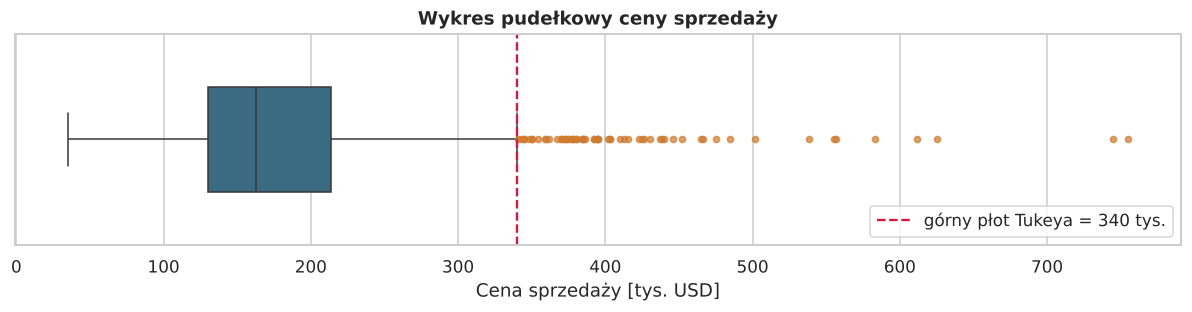

Wartości odstające (reguła 1,5·IQR): 61 domów = 4.2% zbioru
   poniżej dolnego płotu (3 938 USD): 0
   powyżej górnego płotu (340 038 USD): 61
   najdroższe domy: 755 000, 745 000, 625 000, 611 657, 582 933 USD


In [11]:
q1, q3 = y.quantile([0.25, 0.75])
iqr = q3 - q1
plot_dolny, plot_gorny = q1 - 1.5 * iqr, q3 + 1.5 * iqr
odstajace = y[(y < plot_dolny) | (y > plot_gorny)]

fig, ax = plt.subplots(figsize=(11, 3))
sns.boxplot(x=y, ax=ax, color=NIEBIESKI, width=0.5,
            flierprops=dict(marker="o", markerfacecolor=POMARANCZ, markeredgecolor=POMARANCZ,
                            markersize=4, alpha=0.7))
ax.axvline(plot_gorny, color="crimson", ls="--", lw=1.5, label=f"górny płot Tukeya = {plot_gorny / 1000:.0f} tys.")
ax.set(title="Wykres pudełkowy ceny sprzedaży", xlabel="Cena sprzedaży [tys. USD]")
ax.xaxis.set_major_formatter(tys)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

print(f"Wartości odstające (reguła 1,5·IQR): {len(odstajace)} domów = {100 * len(odstajace) / len(y):.1f}% zbioru")
print(f"   poniżej dolnego płotu ({plot_dolny:,.0f} USD): {(y < plot_dolny).sum()}".replace(",", " "))
print(f"   powyżej górnego płotu ({plot_gorny:,.0f} USD): {(y > plot_gorny).sum()}".replace(",", " "))
print("   najdroższe domy: " + ", ".join(f"{v:,.0f}".replace(",", " ") for v in y.nlargest(5)) + " USD")

**Odpowiedź:**

- **Tak, są wartości odstające, ale tylko „w górę”.** Według reguły Tukeya (1,5·IQR) odstaje 61 domów (4,2%) o cenie powyżej ok. 340 tys. USD. Nie ma ani jednego domu odstającego „w dół”, bo dolny płot wypada poniżej minimum zbioru.
- Wąsy i „pudełko” są niesymetryczne: górny wąs jest dłuższy, a odstające punkty ciągną się aż do 755 tys. USD. Potwierdza to skośność prawostronną z histogramu.
- **Co mogą oznaczać bardzo drogie domy?** Analizujemy to w sekcji 2.5, ale już tu warto zaznaczyć, że to nie wygląda na błędy w danych, tylko na odrębny segment rynku.

### 2.3 Statystyki: min, max, średnia, mediana, Q₁, Q₃, IQR

In [12]:
statystyki = pd.Series({
    "min": y.min(),
    "Q1 (25. percentyl)": q1,
    "mediana": y.median(),
    "średnia": y.mean(),
    "Q3 (75. percentyl)": q3,
    "max": y.max(),
    "IQR = Q3 − Q1": iqr,
    "odchylenie standardowe": y.std(),
}, name="SalePrice [USD]")

display(statystyki.map(lambda v: f"{v:,.0f}".replace(",", " ")).to_frame())
print(f"Średnia / mediana = {y.mean() / y.median():.2f}  (średnia jest o {100 * (y.mean() / y.median() - 1):.0f}% wyższa od mediany)")

,SalePrice [USD]
min,34 900
Q1 (25. percentyl),129 975
mediana,163 000
średnia,180 921
Q3 (75. percentyl),214 000
max,755 000
IQR = Q3 − Q1,84 025
odchylenie standardowe,79 443


Średnia / mediana = 1.11  (średnia jest o 11% wyższa od mediany)


| Statystyka | Wartość (USD) |
|---|---|
| min | 34 900 |
| Q₁ | 129 975 |
| **mediana** | **163 000** |
| **średnia** | **180 921** |
| Q₃ | 214 000 |
| max | 755 000 |
| IQR | 84 025 |

**Odpowiedź:** środkowe 50% domów kosztuje od ok. 130 do 214 tys. USD (rozstęp ćwiartkowy ≈ 84 tys.). **Mediana (163 tys.) jest niższa od średniej (181 tys.) o ok. 11%.** Zwykle taka różnica świadczy o skośności prawostronnej: nieliczne bardzo drogie domy podnoszą średnią, a mediana jest na nie odporna. Dla „typowej” ceny rozsądniej więc podawać **medianę**.

### 2.4 Czy ceny mają rozkład normalny?

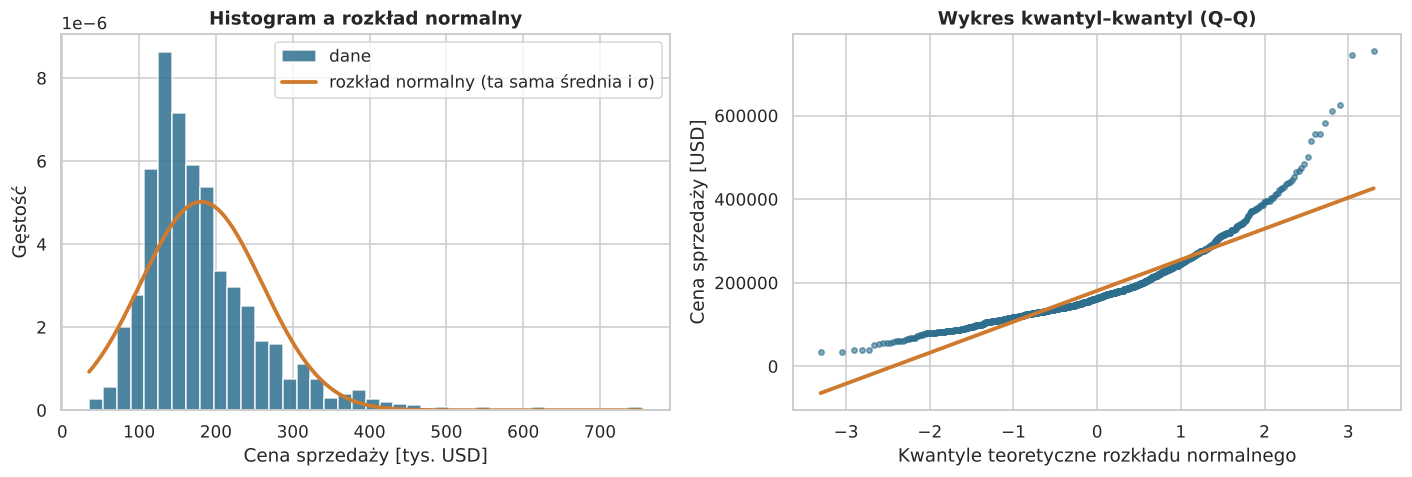

Skośność: 1.88   Kurtoza nadmiarowa: 6.54   (dla rozkładu normalnego obie ≈ 0)
Test Shapiro–Wilka: W = 0.870, p = 3.2e-33


In [13]:
fig, osie = plt.subplots(1, 2, figsize=(13, 4.5))

# lewy panel: histogram z nałożoną krzywą rozkładu normalnego o tej samej średniej i odchyleniu
ax = osie[0]
ax.hist(y, bins=40, density=True, color=NIEBIESKI, edgecolor="white", alpha=0.85, label="dane")
xs = np.linspace(y.min(), y.max(), 400)
ax.plot(xs, stats.norm.pdf(xs, y.mean(), y.std()), color=POMARANCZ, lw=2.5, label="rozkład normalny (ta sama średnia i σ)")
ax.set(title="Histogram a rozkład normalny", xlabel="Cena sprzedaży [tys. USD]", ylabel="Gęstość")
ax.xaxis.set_major_formatter(tys)
ax.legend()

# prawy panel: wykres kwantyl–kwantyl; przy rozkładzie normalnym punkty leżałyby na prostej
ax = osie[1]
stats.probplot(y, dist="norm", plot=ax)
ax.get_lines()[0].set(markerfacecolor=NIEBIESKI, markeredgecolor=NIEBIESKI, markersize=3.5, alpha=0.6)
ax.get_lines()[1].set(color=POMARANCZ, lw=2.5)
ax.set(title="Wykres kwantyl–kwantyl (Q–Q)", xlabel="Kwantyle teoretyczne rozkładu normalnego",
       ylabel="Cena sprzedaży [USD]")
plt.tight_layout()
plt.show()

W, p = stats.shapiro(y)
print(f"Skośność: {y.skew():.2f}   Kurtoza nadmiarowa: {y.kurt():.2f}   (dla rozkładu normalnego obie ≈ 0)")
print(f"Test Shapiro–Wilka: W = {W:.3f}, p = {p:.1e}")

**Odpowiedź: nie, ceny nie mają rozkładu normalnego.**

- **Histogram jest asymetryczny.** Ma długi prawy ogon, a krzywa normalna nie pasuje ani do szczytu, ani do ogona.
- **Wykres Q–Q:** punkty wyraźnie odchylają się od prostej. W prawym górnym rogu ceny najdroższych domów są znacznie wyższe, niż wynikałoby z rozkładu normalnego (ciężki prawy ogon). W lewym dolnym rogu najtańsze domy są droższe, niż przewiduje rozkład normalny (lewy ogon jest „krótszy”). Razem daje to krzywą w kształcie litery J, typową dla skośności prawostronnej.
- **Miary liczbowe:** skośność ≈ 1,88 (dla normalnego 0) i kurtoza nadmiarowa ≈ 6,5 (dla normalnego 0) oznaczają ogon znacznie cięższy niż normalny. Test Shapiro–Wilka odrzuca normalność (p ≈ 3·10⁻³³). Przy ponad tysiącu obserwacji test odrzuciłby nawet niewielkie odchylenia, więc o wniosku decydują głównie wykresy i skośność, a test jest tylko potwierdzeniem.
- **Konsekwencja:** jeśli kiedyś będziemy budować modele, które zakładają rozkład normalny (np. regresję liniową), cenę trzeba będzie przekształcić (typowo logarytmem). W tym notatniku tego nie robimy, bo to wykracza poza zakres zadania.

### 2.5 Co mogą oznaczać bardzo drogie domy?

Porównajmy 61 domów odstających „w górę” z resztą zbioru, żeby ustalić, czy to błędy w danych, czy odrębny segment rynku.

Mediany cech:


,drogie (n=61),pozostałe (n=1399),stosunek
powierzchnia mieszkalna [sq ft],2364.0,1437.0,1.65
powierzchnia piwnicy [sq ft],1856.0,973.0,1.91
powierzchnia działki [sq ft],13682.0,9317.0,1.47
jakość wykończenia (1–10),9.0,6.0,1.50
liczba pomieszczeń nad gruntem,9.0,6.0,1.50
miejsca w garażu,3.0,2.0,1.50
rok budowy,2006.0,1971.0,1.02


Udział domów o jakości ≥ 8: drogie 95% vs pozostałe 12%

Dzielnice, w których najczęściej trafiają się drogie domy:


,drogie,wszystkie domy w dzielnicy,% drogich w dzielnicy
Neighborhood,,,
NridgHt,27,77,35
NoRidge,11,41,27
StoneBr,9,25,36
Crawfor,3,51,6
Timber,3,38,8
Somerst,2,86,2


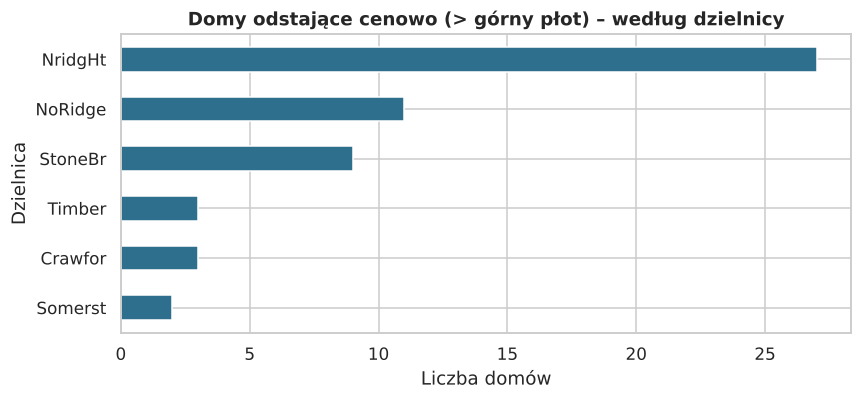

In [14]:
drogie = df[df[CEL] > plot_gorny]
reszta = df[df[CEL] <= plot_gorny]

cechy = {
    "GrLivArea": "powierzchnia mieszkalna [sq ft]",
    "TotalBsmtSF": "powierzchnia piwnicy [sq ft]",
    "LotArea": "powierzchnia działki [sq ft]",
    "OverallQual": "jakość wykończenia (1–10)",
    "TotRmsAbvGrd": "liczba pomieszczeń nad gruntem",
    "GarageCars": "miejsca w garażu",
    "YearBuilt": "rok budowy",
}
profil = pd.DataFrame({
    f"drogie (n={len(drogie)})": drogie[list(cechy)].median(),
    f"pozostałe (n={len(reszta)})": reszta[list(cechy)].median(),
})
profil.index = [cechy[k] for k in profil.index]
profil["stosunek"] = (profil.iloc[:, 0] / profil.iloc[:, 1]).round(2)
print("Mediany cech:")
display(profil)

print(f"Udział domów o jakości ≥ 8: drogie {100 * (drogie.OverallQual >= 8).mean():.0f}% vs pozostałe {100 * (reszta.OverallQual >= 8).mean():.0f}%")

lok = pd.DataFrame({
    "drogie": drogie.Neighborhood.value_counts(),
    "wszystkie domy w dzielnicy": df.Neighborhood.value_counts(),
}).dropna().sort_values("drogie", ascending=False).head(6).astype(int)
lok["% drogich w dzielnicy"] = (100 * lok["drogie"] / lok["wszystkie domy w dzielnicy"]).round(0).astype(int)
print("\nDzielnice, w których najczęściej trafiają się drogie domy:")
display(lok)

fig, ax = plt.subplots(figsize=(8, 3.8))
lok["drogie"].sort_values().plot.barh(ax=ax, color=NIEBIESKI)
ax.set(title="Domy odstające cenowo (> górny płot) – według dzielnicy", xlabel="Liczba domów", ylabel="Dzielnica")
plt.tight_layout()
plt.show()

**Odpowiedź:** bardzo drogie domy to **segment premium**, a nie błędy w danych:

- są **znacznie większe** (mediana powierzchni mieszkalnej 2364 vs 1437 sq ft; piwnica 1856 vs 973 sq ft),
- mają **dużo wyższą jakość wykonania** (mediana 9 vs 6; aż 95% z nich ma ocenę ≥ 8, wśród pozostałych 12%),
- są **nowsze** (mediana roku budowy 2006 vs 1971) i mają więcej pomieszczeń i miejsc w garażu,
- są **skupione w kilku dzielnicach**: `NridgHt`, `NoRidge` i `StoneBr` dają 47 z 61 takich domów (77%). Wśród wszystkich domów w tych dzielnicach drogich jest od 27% do 36%.

Wniosek: ogon rozkładu to prawdziwe, ale rzadkie zjawisko, czyli luksusowe, duże i nowe domy w kilku prestiżowych dzielnicach. Nie wolno ich więc usuwać „bo odstają”. To one jednak powodują, że średnia jest wyższa od mediany, a rozkład skośny.

---
## 3. Co wpływa na cenę domu?

**Hipoteza do sprawdzenia:** „Większe domy są droższe”.

### 3.1 Zmienne związane z powierzchnią

Zgodnie ze wskazówką szukamy w nazwach kolumn ciągów `Area` i `SF`:

In [15]:
kol_pow = [c for c in df.columns if "Area" in c or "SF" in c]

opis_pow = {
    "LotArea": ("działka", "powierzchnia działki"),
    "MasVnrArea": ("dom", "powierzchnia okładziny murowanej"),
    "BsmtFinSF1": ("piwnica", "wykończona powierzchnia piwnicy (typ 1)"),
    "BsmtFinSF2": ("piwnica", "wykończona powierzchnia piwnicy (typ 2)"),
    "BsmtUnfSF": ("piwnica", "niewykończona powierzchnia piwnicy"),
    "TotalBsmtSF": ("piwnica", "całkowita powierzchnia piwnicy"),
    "1stFlrSF": ("dom", "powierzchnia parteru"),
    "2ndFlrSF": ("dom", "powierzchnia drugiego piętra"),
    "LowQualFinSF": ("dom", "powierzchnia o niskiej jakości wykończenia (wszystkie piętra)"),
    "GrLivArea": ("dom", "powierzchnia mieszkalna nad poziomem gruntu"),
    "GarageArea": ("garaż", "powierzchnia garażu"),
    "WoodDeckSF": ("dodatki", "powierzchnia drewnianego tarasu"),
    "OpenPorchSF": ("dodatki", "powierzchnia otwartego ganku"),
    "PoolArea": ("dodatki", "powierzchnia basenu"),
}
assert set(kol_pow) == set(opis_pow), "lista kolumn powierzchniowych różni się od opisanej"

tab_pow = pd.DataFrame({
    "czego dotyczy": [opis_pow[c][0] for c in kol_pow],
    "opis": [opis_pow[c][1] for c in kol_pow],
    "mediana [sq ft]": [df[c].median() for c in kol_pow],
    "domy z wartością > 0": [int((df[c] > 0).sum()) for c in kol_pow],
}, index=kol_pow)
print(f"Znaleziono {len(kol_pow)} kolumn powierzchniowych:")
display(tab_pow)

# która z nich jest „powierzchnią mieszkalną” całego domu?
print("GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF dla wszystkich domów:",
      bool((df.GrLivArea == df["1stFlrSF"] + df["2ndFlrSF"] + df.LowQualFinSF).all()))
print("TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF dla wszystkich domów:",
      bool((df.TotalBsmtSF == df.BsmtFinSF1 + df.BsmtFinSF2 + df.BsmtUnfSF).all()))

Znaleziono 14 kolumn powierzchniowych:


,czego dotyczy,opis,mediana [sq ft],domy z wartością > 0
LotArea,działka,powierzchnia działki,9478.5,1460
MasVnrArea,dom,powierzchnia okładziny murowanej,0.0,591
BsmtFinSF1,piwnica,wykończona powierzchnia piwnicy (typ 1),383.5,993
BsmtFinSF2,piwnica,wykończona powierzchnia piwnicy (typ 2),0.0,167
BsmtUnfSF,piwnica,niewykończona powierzchnia piwnicy,477.5,1342
TotalBsmtSF,piwnica,całkowita powierzchnia piwnicy,991.5,1423
1stFlrSF,dom,powierzchnia parteru,1087.0,1460
2ndFlrSF,dom,powierzchnia drugiego piętra,0.0,631
LowQualFinSF,dom,powierzchnia o niskiej jakości wykończenia (ws...,0.0,26
GrLivArea,dom,powierzchnia mieszkalna nad poziomem gruntu,1464.0,1460


GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF dla wszystkich domów: True
TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF dla wszystkich domów: True


**Odpowiedź:** wskazówka daje **14 kolumn**. Można je pogrupować na powierzchnie: działki (`LotArea`), domu (`1stFlrSF`, `2ndFlrSF`, `LowQualFinSF`, `GrLivArea`, `MasVnrArea`), piwnicy (`BsmtFinSF1`, `BsmtFinSF2`, `BsmtUnfSF`, `TotalBsmtSF`), garażu (`GarageArea`) i dodatków (taras, ganek, basen).

Kolumny nie są niezależne. Sprawdzenie na danych pokazuje, że **`GrLivArea` = `1stFlrSF` + `2ndFlrSF` + `LowQualFinSF`** (dokładnie, dla każdego domu), a `TotalBsmtSF` to suma trzech składników piwnicy. Jako **„powierzchnię mieszkalną”** do dalszej analizy wybieramy więc **`GrLivArea`**. To zbiorcza miara powierzchni użytkowej domu nad poziomem gruntu, a jej składniki (parter, piętro) już w niej zawarto. Elementy, które ma tylko część domów (np. basen: 7 domów), nie nadają się na ogólną miarę wielkości domu.

### 3.2 Wykres punktowy: powierzchnia mieszkalna vs cena

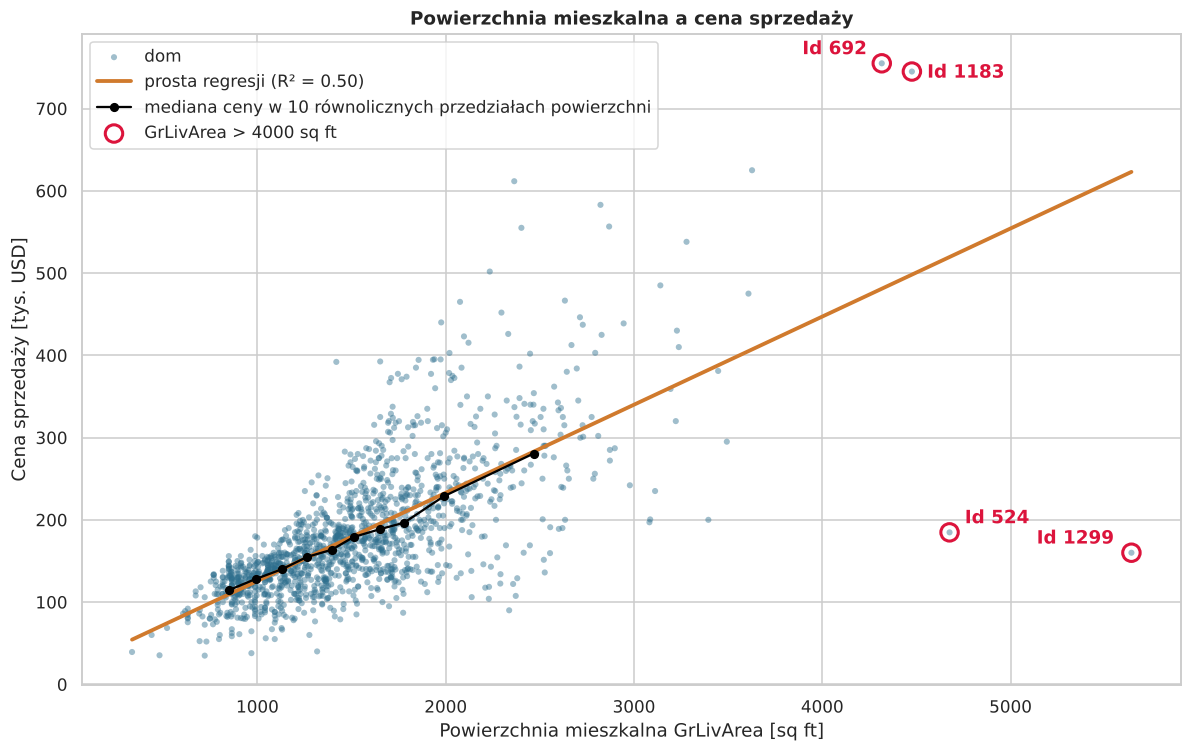

Korelacja Pearsona:  r = 0.709   (R² = 0.502: powierzchnia „wyjaśnia” ok. 50% zmienności ceny)


Korelacja Spearmana: ρ = 0.731
Nachylenie prostej: 107 USD za każdy sq ft (≈ 1 153 USD za m²)

Odchylenie standardowe reszt w grupach powierzchni (małe / średnie / duże domy):


,σ reszt [USD]
GrLivArea,
małe,25877.0
średnie,43641.0
duże,82808.0


In [16]:
x = df["GrLivArea"]
reg = stats.linregress(x, y)
mediany = df.groupby(pd.qcut(x, 10), observed=True).agg(x=("GrLivArea", "median"), y=(CEL, "median"))
odd = df[df.GrLivArea > 4000]

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(x, y, s=16, alpha=0.45, color=NIEBIESKI, edgecolor="none", label="dom")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, reg.intercept + reg.slope * xs, color=POMARANCZ, lw=2.5,
        label=f"prosta regresji (R² = {reg.rvalue ** 2:.2f})")
ax.plot(mediany.x, mediany.y, "o-", color="black", ms=5, lw=1.5,
        label="mediana ceny w 10 równolicznych przedziałach powierzchni")
ax.scatter(odd.GrLivArea, odd[CEL], s=130, facecolor="none", edgecolor="crimson", lw=2, label="GrLivArea > 4000 sq ft")
przesuniecia = {524: (10, 6), 692: (-52, 6), 1183: (10, -4), 1299: (-62, 6)}
for _, r in odd.iterrows():
    ax.annotate(f"Id {int(r.Id)}", (r.GrLivArea, r[CEL]), textcoords="offset points",
                xytext=przesuniecia[int(r.Id)], color="crimson", fontweight="bold")
ax.set(title="Powierzchnia mieszkalna a cena sprzedaży",
       xlabel="Powierzchnia mieszkalna GrLivArea [sq ft]", ylabel="Cena sprzedaży [tys. USD]")
ax.yaxis.set_major_formatter(tys)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

r_p = x.corr(y)
r_s = x.corr(y, method="spearman")
print(f"Korelacja Pearsona:  r = {r_p:.3f}   (R² = {r_p ** 2:.3f}: powierzchnia „wyjaśnia” ok. {100 * r_p ** 2:.0f}% zmienności ceny)")
print(f"Korelacja Spearmana: ρ = {r_s:.3f}")
print(f"Nachylenie prostej: {reg.slope:.0f} USD za każdy sq ft (≈ {reg.slope / 0.092903:,.0f} USD za m²)".replace(",", " "))

# czy rozrzut wokół prostej jest stały? odchylenie reszt w trzech równolicznych grupach powierzchni
reszty = y - (reg.intercept + reg.slope * x)
print("\nOdchylenie standardowe reszt w grupach powierzchni (małe / średnie / duże domy):")
display(reszty.groupby(pd.qcut(x, 3, labels=["małe", "średnie", "duże"]), observed=True).std().round(0).to_frame("σ reszt [USD]"))

**Odpowiedź:**

- **Czy zależność jest wyraźna? Tak.** Chmura punktów układa się wyraźnie z lewego dołu do prawego góry. Korelacja Pearsona wynosi **r ≈ 0,71** (Spearmana ρ ≈ 0,73). Powierzchnia mieszkalna sama „wyjaśnia” ok. **50% zmienności ceny** (R² ≈ 0,50). **Hipoteza „większe domy są droższe” potwierdza się:** przeciętnie każdy dodatkowy sq ft to ok. 107 USD (≈ 1150 USD za m²), czyli 100 sq ft więcej to ok. 10,7 tys. USD.
- **Czy jest liniowa? W przybliżeniu tak.** Mediany w kolejnych przedziałach powierzchni (czarna linia) układają się prawie wzdłuż prostej regresji, więc nie widać wyraźnego zakrzywienia. Zależność **nie jest jednak „czysto” liniowa**, bo rozrzut rośnie z powierzchnią. Odchylenie reszt dla małych, średnich i dużych domów wynosi ok. 26 / 44 / 83 tys. USD. Cena małych domów jest dość dobrze przewidywalna na podstawie powierzchni, a duże domy mogą kosztować bardzo różnie (kształt „rozwachlarzonego lejka”). Oznacza to, że ceny dużych domów zależą w znacznym stopniu od innych czynników (np. jakości czy lokalizacji), których tu nie badamy.
- Połowa zmienności ceny pozostaje niewyjaśniona samą powierzchnią, więc **wielkość jest ważnym, ale nie jedynym czynnikiem ceny**.

### 3.3 Dziwne obserwacje: kim są?

Na wykresie wyróżniają się cztery domy o powierzchni mieszkalnej powyżej 4000 sq ft (to ponad 2,5× mediana). Dwa leżą **wysoko** na trendzie, a dwa **dramatycznie poniżej** niego.

In [17]:
odd = df[df.GrLivArea > 4000].copy()
odd["cena wg prostej"] = (reg.intercept + reg.slope * odd.GrLivArea).round(-3)
odd["reszta"] = odd[CEL] - odd["cena wg prostej"]

kolumny = ["Id", "GrLivArea", CEL, "cena wg prostej", "reszta", "OverallQual", "Neighborhood",
           "YearBuilt", "LotArea", "SaleType", "SaleCondition"]
display(odd[kolumny].sort_values("reszta").reset_index(drop=True))

bez = df[~df.Id.isin([524, 1299])]
reg2 = stats.linregress(bez.GrLivArea, bez[CEL])
print("Wpływ dwóch domów z niską ceną (Id 524 i 1299) na wyniki:")
print(f"   z nimi:  r = {r_p:.3f}, R² = {r_p ** 2:.3f}, nachylenie = {reg.slope:.0f} USD/sq ft")
print(f"   bez nich: r = {reg2.rvalue:.3f}, R² = {reg2.rvalue ** 2:.3f}, nachylenie = {reg2.slope:.0f} USD/sq ft")

,Id,GrLivArea,SalePrice,cena wg prostej,reszta,OverallQual,Neighborhood,YearBuilt,LotArea,SaleType,SaleCondition
0,1299,5642,160000,623000.0,-463000.0,10,Edwards,2008,63887,New,Partial
1,524,4676,184750,520000.0,-335250.0,10,Edwards,2007,40094,New,Partial
2,1183,4476,745000,498000.0,247000.0,10,NoRidge,1996,15623,WD,Abnorml
3,692,4316,755000,481000.0,274000.0,10,NoRidge,1994,21535,WD,Normal


Wpływ dwóch domów z niską ceną (Id 524 i 1299) na wyniki:
   z nimi:  r = 0.709, R² = 0.502, nachylenie = 107 USD/sq ft
   bez nich: r = 0.735, R² = 0.540, nachylenie = 115 USD/sq ft


**Kim są te obserwacje?**

**1. `Id` 524 i `Id` 1299: prawdziwe anomalie.** To domy o powierzchni 4676 i 5642 sq ft (największy dom w zbiorze), ale cenach zaledwie **184 750 i 160 000 USD**, czyli o ponad 300 i 460 tys. USD poniżej prostej regresji. Mają wspólne cechy:
  - dzielnica `Edwards`, dom nowy (`YearBuilt` 2007 i 2008, `SaleType` = `New`),
  - warunek sprzedaży **`Partial`**: wg opisu zbioru dom nie był jeszcze ukończony w momencie ostatniej oceny (typowe dla nowych domów),
  - bardzo duże działki (40 i 64 tys. sq ft) i najwyższa ocena jakości (10).

  Cena wygląda więc na **nieadekwatną do wielkości domu** (np. sprzedaż domu w trakcie budowy), a nie na typową transakcję. Jest to hipoteza oparta na wartościach `SaleType` i `SaleCondition`, dane tego nie potwierdzają wprost. Te dwa punkty osłabiają obserwowaną zależność: **po ich usunięciu korelacja rośnie z 0,71 do 0,73, a R² z 0,50 do 0,54**. Autor zbioru (D. De Cock, 2011) zaleca w publikacji opisującej dane usunięcie domów powyżej 4000 sq ft jako nietypowych.

**2. `Id` 692 i `Id` 1183: prawdziwe, bardzo drogie domy.** To dwa **najdroższe** domy w zbiorze (755 i 745 tys. USD, powierzchnia 4316 i 4476 sq ft), z dzielnicy `NoRidge`, o najwyższej ocenie jakości (10), zbudowane w latach 90. Leżą powyżej prostej regresji (tj. są droższe, niż wynika z samej powierzchni), co wynika z ich jakości i lokalizacji (por. sekcja 2.5). To **poprawne obserwacje**: wpisują się w segment premium i nie ma powodu ich usuwać. `Id` 1183 miał nietypowy warunek sprzedaży (`Abnorml`), ale cena nie odbiega od logiki rynku.

**3. Duże domy poniżej trendu, ale wyjaśnione.** Na wykresie widać też kilka domów o powierzchni 3000–3500 sq ft sprzedanych za ok. 200 tys. USD (m.in. `Id` 636, 1032, 1174). To **stare domy** (zbudowane w latach 1914–1946) w tańszych dzielnicach (`SWISU`, `ClearCr`) i o przeciętnej jakości (5–7). Są poniżej prostej, bo na cenę wpływa też wiek, jakość i lokalizacja, a nie tylko powierzchnia. Nie są anomaliami.

**Wniosek:** zbiór zawiera dwa nietypowe domy o ogromnej powierzchni i nieproporcjonalnie niskiej cenie. Warto je oznaczyć lub usunąć przed modelowaniem, bo zaniżają siłę zależności powierzchni i ceny.

---
## Podsumowanie wniosków

| Pytanie | Wniosek |
|---|---|
| **Zmienna docelowa** | `SalePrice` (cena sprzedaży w USD), zmienna ciągła, więc zadanie regresji. |
| **Typy zmiennych** | 38 liczbowych i 43 tekstowe. Tekstowe to kategorie (nie swobodny tekst). Część liczbowych to kody, oceny porządkowe lub daty, więc typ techniczny nie wystarcza. |
| **Braki danych** | 19 kolumn z `NA`, ale w 15 z nich `NA` oznacza **„brak elementu”** (garaż, piwnica, basen…), a nie brak informacji. Prawdziwe braki ma tylko 6 kolumn (`LotFrontage` 17,7%, `MasVnrType` i `MasVnrArea`, `Electrical`, pojedyncze w piwnicy). |
| **Rozkład cen** | Prawoskośny (skośność ≈ 1,88), jednoszczytowy, **nienormalny**. Mediana 163 tys. USD < średnia 181 tys. USD. |
| **Wartości odstające** | 61 domów (4,2%) powyżej ok. 340 tys. USD, tylko „w górę”. To **segment premium** (duże, nowe, wysokiej jakości, w kilku dzielnicach), a nie błędy. |
| **Większe domy są droższe?** | **Tak:** r ≈ 0,71, R² ≈ 0,50, ok. 107 USD za sq ft. Zależność jest w przybliżeniu liniowa, ale rozrzut rośnie wraz z wielkością domu. |
| **Dziwne obserwacje** | Dwa domy >4000 sq ft (`Id` 524, 1299) sprzedane za 160–185 tys. USD, `SaleCondition` = `Partial`. Prawdopodobnie transakcje nietypowe. Dwa inne (`Id` 692, 1183) to najdroższe domy w zbiorze i są poprawne. |